In [354]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

from pathlib import Path
from collections import Counter
import re

## Data Dictionary

Below is the description of the columns provided by the competition organizers:

| Variable | Definition | Key / Note |
| :--- | :--- | :--- |
| **survival** | Survival | `0` = No, `1` = Yes |
| **pclass** | Ticket class | `1` = 1st, `2` = 2nd, `3` = 3rd |
| **sex** | Sex | - |
| **Age** | Age in years | Requires missing value imputation |
| **sibsp** | # of siblings / spouses aboard the Titanic | - |
| **parch** | # of parents / children aboard the Titanic | - |
| **ticket** | Ticket number | String feature with high cardinality |
| **fare** | Passenger fare | Continuous numerical feature |
| **cabin** | Cabin number | High missing rate (potential for deck extraction) |
| **embarked** | Port of Embarkation | `C` = Cherbourg, `Q` = Queenstown, `S` = Southampton |

In [2]:
data_path = Path("data") / "train.csv"
titanic_train_data = pd.read_csv(data_path)

titanic_train_data = titanic_train_data.drop(columns="PassengerId")

### First look at the data

In [3]:
titanic_train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


In [5]:
titanic_train_data.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


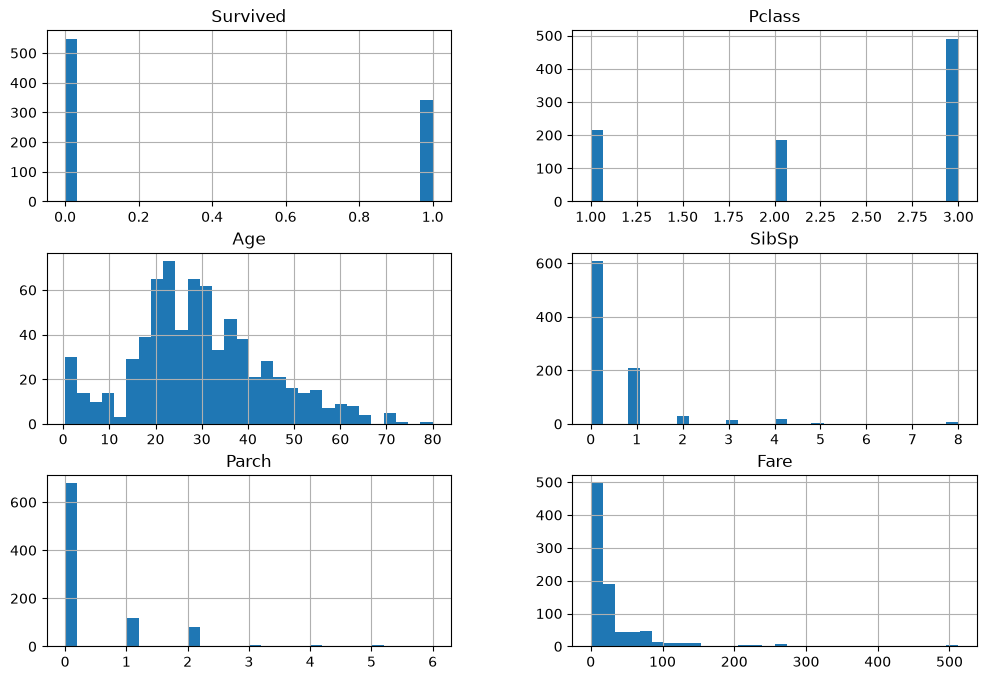

In [6]:
titanic_train_data.hist(bins=30, figsize=(12, 8))
plt.show()

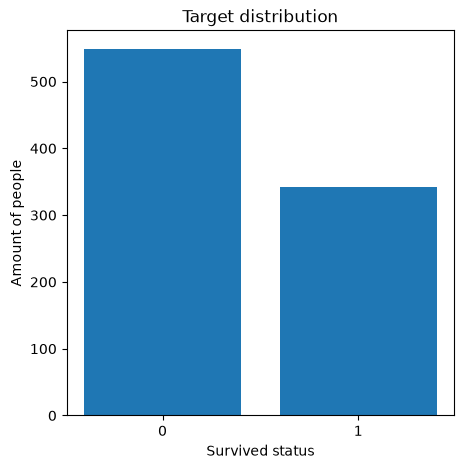

In [8]:
main_feature_distribution = titanic_train_data["Survived"].value_counts()

plt.figure(figsize=(5, 5))
plt.bar(
    x=main_feature_distribution.index,
    height=main_feature_distribution.values
)
plt.xticks(ticks=[0, 1])
plt.xlabel("Survived status")
plt.ylabel("Amount of people")
plt.title("Target distribution")

plt.show()

### Train/Test split

In [11]:
train_set, test_set = train_test_split(
    titanic_train_data, 
    test_size=0.2, 
    stratify=titanic_train_data["Survived"], 
    random_state=42
)

### EDA (Exploratory Data Analysis)

**Name**

The columns name is composed of passengers names. We can use it in order to fill the age column by extracting the type of passenger and calculating the mean age of each group.

In [32]:
names_text = ', '.join(train_set["Name"].values).split(" ")
names_most_common_words = Counter(names_text)
print("Top 10 most common words in Name column is:")
for i in names_most_common_words.most_common(10):
    print(i[0], i[1])

Top 10 most common words in Name column is:
Mr. 412
Miss. 141
Mrs. 107
William 37
Master. 31
John 21
Henry 16
John, 15
Charles 14
Henry, 12


There are 5 groups inside this text:
- Mr
- Miss
- Mrs
- Master
- Other

We can create new feature "title" using this data, and then based on this information work with age column

In [147]:
patterns = r"(Mr\.|Mrs\.|Miss\.|Master\.)"

def passenger_types(X):
    return X.apply(lambda x: re.findall(patterns, x)[0][:-1] if re.findall(patterns, x) else "Other").to_frame(name="passenger_types")

def passenger_types_name(function_transformer, feature_names_in):
    return ["passenger_types"]

name_transformer = FunctionTransformer(
    passenger_types,
    feature_names_out=passenger_types_name
)
name_pipeline = make_pipeline(
    name_transformer,
    OneHotEncoder(handle_unknown="ignore")
)

# res = name_pipeline.fit_transform(titanic_train_data["Name"])
# res.toarray()

**Age**

In [195]:
titanic_train_data_copy = titanic_train_data.copy()
titanic_train_data_copy.index.name = "index"
titanic_train_data_copy = titanic_train_data_copy.reset_index()
titanic_train_data_copy["Sex"] = titanic_train_data_copy["Sex"].map({"male": 0, "female": 1})

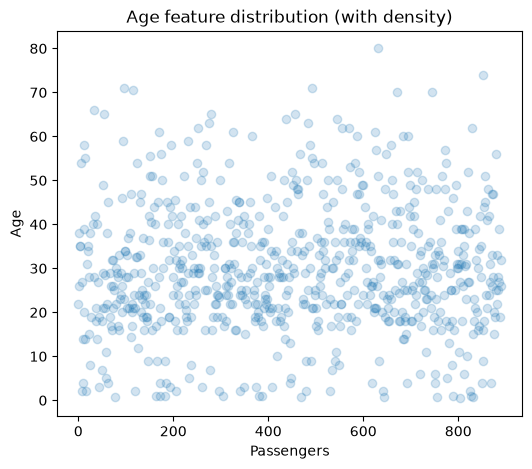

In [197]:
plt.figure(figsize=(6, 5))

plt.scatter(
    x=titanic_train_data.index,
    y=titanic_train_data["Age"],
    alpha=0.2
)

plt.xlabel("Passengers")
plt.ylabel("Age")
plt.title("Age feature distribution (with density)")

plt.show()

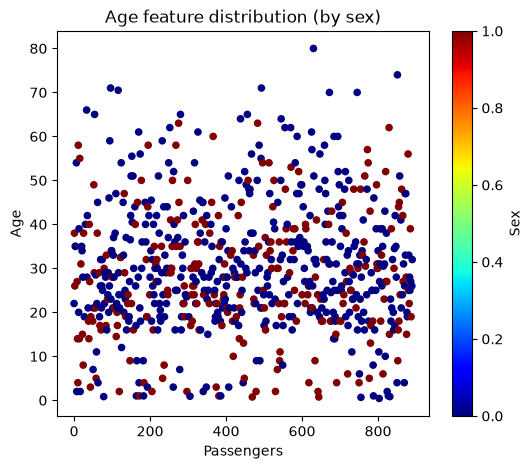

In [199]:
titanic_train_data_copy.plot(
    kind="scatter",
    x="index",
    y="Age",
    c="Sex",
    cmap="jet",
    figsize=(6, 5)
)
plt.xlabel("Passengers")
plt.ylabel("Age")
plt.title("Age feature distribution (by sex)")

plt.show()

In [362]:
class AgeFillEstimator(BaseEstimator, TransformerMixin):
    """
    Trasnforming Age using Name
    """

    def __init__(self, group_idx=0, target_idx=1):
        self.target_idx = target_idx
        self.group_idx = group_idx

    def fit(self, X, y=None):
        X_tranform = X.copy()
        if not isinstance(X_tranform, pd.DataFrame):
            X_tranform = pd.DataFrame(X_tranform, columns=["Name", "Age"])
        cols = X_tranform.columns
        X_tranform = pd.concat([X_tranform, passenger_types(X_tranform[cols[self.group_idx]])], axis=1)
        self.age_means = X_tranform.groupby(by="passenger_types")[cols[self.target_idx]].mean().round(0)
        return self

    def transform(self, X):
        X_tranform = X.copy()
        if not isinstance(X, pd.DataFrame):
            X_tranform = pd.DataFrame(X_tranform, columns=["Name", "Age"])
        cols = X_tranform.columns
        X_tranform = pd.concat([X_tranform, passenger_types(X_tranform[cols[self.group_idx]])], axis=1)
        X_tranform["temp_col"] = X_tranform["passenger_types"].map(self.age_means)
        # temp_col = df_1["passenger_types"].map(self.age_means)
        filled_age = np.where(X_tranform[cols[self.target_idx]].isna(), X_tranform["temp_col"], X_tranform[cols[self.target_idx]])
        return filled_age.reshape(-1, 1)

    def get_feature_names_out(self, names=None):
        return ["filled_age"]


age_pipeline = make_pipeline(
    AgeFillEstimator(),
    StandardScaler()
)
# age_estimator = AgeFillEstimator()
# example_new_feature_values = res.fit_transform(titanic_train_data_copy[["Name", "Age"]].values)
# age_pipeline.fit_transform(titanic_train_data_copy[["Name", "Age"]].values)